### Configuration

1. Update the variable "original_data_root" on line 2 of "recipes/investigation_recipe.json" to the path at which the in vivo data is stored. For example:
> "original_data_root": "/Users/james/IsbisterEtAl-SciRep2021-Data/",

2. Update the variable "figures_root_directory" on line 3 of "recipes/investigation_recipe.json" to the directory you would like the output of the analyses to be stored. For example:
> "figures_root_directory": "/Users/james/IsbisterEtAl-SciRep2021-Figures/",

3. Update the variable "number_of_processors" on line 4 of "recipes/investigation_recipe.json" to the number of threads you would like to use (initially set to 8).


### Run

The script can be run with the following command:


In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import multiprocessing
import spikewarp as sw
from scipy.ndimage import gaussian_filter
from os import listdir
from os.path import isfile, join
import seaborn as sns
sns.set()
from matplotlib.ticker import MultipleLocator
import math
from scipy.stats import linregress

# 1. 成功印出核心數
print(multiprocessing.cpu_count())

# 2. 在 Jupyter 中，讀取正確的 JSON 設定檔路徑
investigation = sw.load_json_recipe("recipes/investigation_recipe.json")

# 3. 繼續執行後續分析
sw.prepare_investigation(investigation)
data_loaders, investigation['determined_cortical_onset_timepoint'] = sw.load_spikes_calc_cort_onset_and_draw_PSTHs(investigation)
sw.prepare_investigation_analysis_recipes(investigation)

12


In [2]:
for data_loader in data_loaders:
    print(data_loader.exc_inh_type_of_each_unit)

['EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'INH' 'EXC' 'EXC' 'INH' 'INH' 'INH' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'EXC' 'EXC' 'INH' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'INH' 'INH']
['EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'INH'
 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'EXC' 'EXC' 'INH' 'EXC'
 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'INH' 'EXC' 'EXC' 'EXC' 'INH' 'EXC'
 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'EXC' 'EXC']
['EXC' 'EXC' 'EXC' 'INH' 'EXC' 'INH' 'INH' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'INH' 'INH' 'INH' 'EXC' 'EXC' 'EXC' 'INH' 'EXC' 'INH' 'INH' 'EXC' 'EXC'
 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'EXC' 'EXC' 'EXC' 'EXC'
 'INH' 'INH' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'EXC' 'EXC']
['EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'INH' 'EXC' 'INH' 'EXC'
 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC' 'INH' 'EXC' 'EXC' 'EXC' 'EXC' 'EXC'
 'EXC' 'E

In [3]:
len(data_loaders)

18

In [20]:
data_loader.number_of_conditions

12

In [21]:
print(len(data_loader.all_channel_unit_spike_trains_for_all_trials))

38


In [8]:
data_loader.number_of_channel_unit_pairs

38

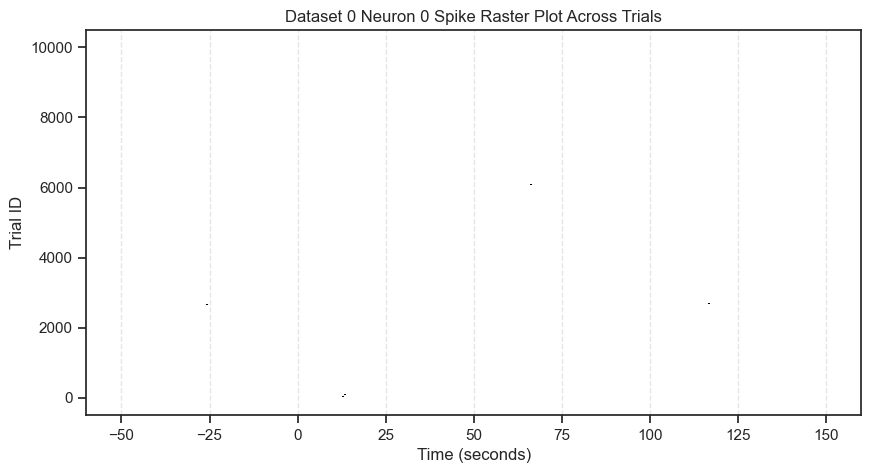

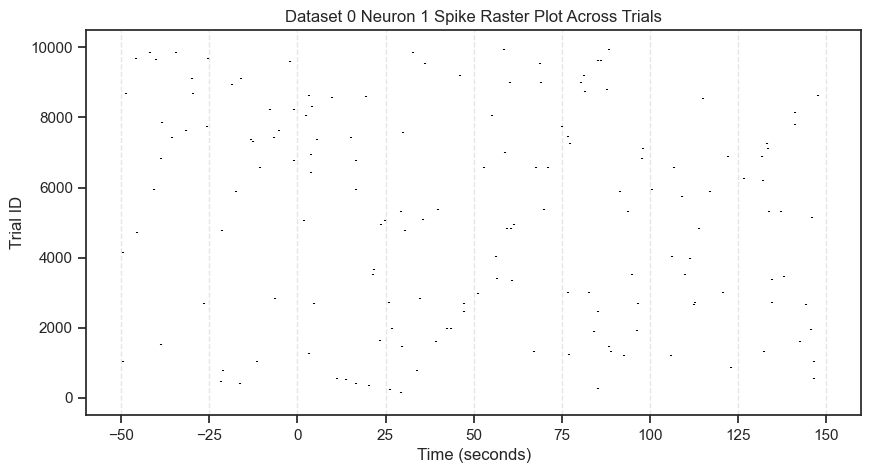

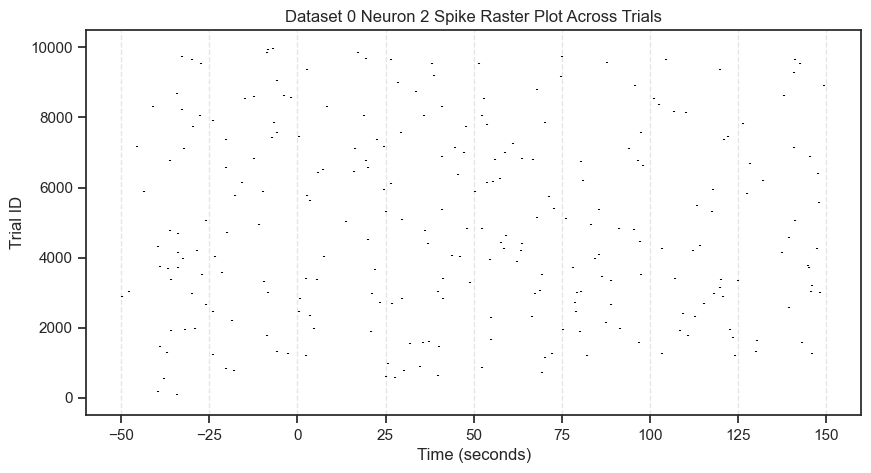

In [29]:
dataset = 0
data_loader = data_loaders[dataset]
# 創建圖表
for neuron in range(3): #len(data_loader.all_channel_unit_spike_trains_for_all_trials)):
    plt.figure(figsize=(10, 5))
    
    # 使用 eventplot 繪製光柵圖
    # lineoffsets: 設定每組資料在 Y 軸的中心位置 [0, 1, 2, 3, etc]
    # linelengths: 設定每個刻度線的長度（高度）
    plt.eventplot(data_loader.all_channel_unit_spike_trains_for_all_trials[neuron], lineoffsets=range(len(data_loader.all_channel_unit_spike_trains_for_all_trials[neuron])), linelengths=0.7, colors='black')
    
    # 設定圖表標籤與標題
    plt.title('Dataset ' + str(dataset) + ' Neuron ' + str(neuron) + ' Spike Raster Plot Across Trials')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Trial ID')
    
    
    # 顯示圖表
    plt.grid(axis='x', linestyle='--', alpha=0.5) # 加入垂直虛線輔助線
    plt.show()